## 06 - Modelagem em duas etapas: ocorrência e intensidade da precipitação

A avaliação da regressão direta evidenciou dificuldade na estimativa de eventos de precipitação intensa, além da predominância de dias secos ou com baixos acumulados.

Como abordagem complementar, o problema de previsão foi dividido em duas etapas. A primeira etapa consiste em classificar a ocorrência de precipitação no dia seguinte, enquanto a segunda estima o volume de chuva apenas para os dias classificados como chuvosos.

Para manter a consistência com as análises anteriores, foi adotado como evento de chuva o acumulado diário igual ou superior a 1 mm. O desenvolvimento e a seleção dos modelos são realizados utilizando apenas o conjunto de treino, com validação temporal por `TimeSeriesSplit`.

In [1]:
import pandas as pd
import numpy as np

# Carrega a base diária
df = pd.read_parquet(
    "../data/gold/a701_2010_2025_diario_horario_sp.parquet"
)

# Data
df["DATA (YYYY-MM-DD)"] = pd.to_datetime(
    df["DATA (YYYY-MM-DD)"]
)

# Variáveis de calendário
df["mes"] = df["DATA (YYYY-MM-DD)"].dt.month
df["dia_ano"] = df["DATA (YYYY-MM-DD)"].dt.dayofyear

df["mes_sin"] = np.sin(2 * np.pi * df["mes"] / 12)
df["mes_cos"] = np.cos(2 * np.pi * df["mes"] / 12)

df["dia_ano_sin"] = np.sin(
    2 * np.pi * df["dia_ano"] / 365.25
)

df["dia_ano_cos"] = np.cos(
    2 * np.pi * df["dia_ano"] / 365.25
)

# Lags de precipitação
df["precipitacao_lag_1"] = df["precipitacao_diaria_mm"].shift(1)
df["precipitacao_lag_2"] = df["precipitacao_diaria_mm"].shift(2)
df["precipitacao_lag_3"] = df["precipitacao_diaria_mm"].shift(3)

# Médias móveis
df["media_movel_3"] = (
    df["precipitacao_diaria_mm"]
    .shift(1)
    .rolling(3)
    .mean()
)

df["media_movel_7"] = (
    df["precipitacao_diaria_mm"]
    .shift(1)
    .rolling(7)
    .mean()
)

# Variáveis meteorológicas defasadas
df["temperatura_lag_1"] = df["temperatura_media"].shift(1)
df["umidade_lag_1"] = df["umidade_media"].shift(1)
df["pressao_lag_1"] = df["pressao_media"].shift(1)
df["vento_lag_1"] = df["vento_medio"].shift(1)

# Features multivariadas
features_multivariadas = [
    "mes_sin",
    "mes_cos",
    "dia_ano_sin",
    "dia_ano_cos",
    "precipitacao_lag_1",
    "precipitacao_lag_2",
    "precipitacao_lag_3",
    "media_movel_3",
    "media_movel_7",
    "temperatura_lag_1",
    "umidade_lag_1",
    "pressao_lag_1",
    "vento_lag_1"
]

alvo = "precipitacao_diaria_mm"

# Base de modelagem
base_modelagem = df[
    ["DATA (YYYY-MM-DD)", alvo] + features_multivariadas
].dropna().copy()

# Split cronológico 80/20
indice_corte = int(len(base_modelagem) * 0.8)

treino = base_modelagem.iloc[:indice_corte].copy()
teste = base_modelagem.iloc[indice_corte:].copy()

print("Base:", len(base_modelagem))
print("Treino:", len(treino))
print("Teste:", len(teste))

Base: 4953
Treino: 3962
Teste: 991


In [2]:
treino_duas_etapas = treino.copy()

treino_duas_etapas["choveu"] = (
    treino_duas_etapas["precipitacao_diaria_mm"] >= 1
).astype(int)

treino_duas_etapas[
    ["precipitacao_diaria_mm", "choveu"]
].head(10)

,precipitacao_diaria_mm,choveu
7,30.2,1
8,0.2,0
9,0.6,0
10,29.2,1
11,2.8,1
20,51.4,1
28,10.0,1
29,0.0,0
30,1.0,1
31,34.2,1


In [3]:
distribuicao_chuva = (
    treino_duas_etapas["choveu"]
    .value_counts()
    .sort_index()
)

percentual_chuva = (
    treino_duas_etapas["choveu"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

print("Quantidade:")
print(distribuicao_chuva)

print("\nPercentual:")
print(percentual_chuva.round(2))

Quantidade:
choveu
0    2736
1    1226
Name: count, dtype: int64

Percentual:
choveu
0    69.06
1    30.94
Name: proportion, dtype: float64


### Etapa 1 - Classificação da ocorrência de chuva

A primeira etapa da abordagem em duas fases consiste em classificar se haverá ou não ocorrência de precipitação no dia seguinte.

Foi considerado como dia chuvoso aquele com precipitação diária igual ou superior a 1 mm. No conjunto de treino, aproximadamente 31% dos registros pertencem à classe de chuva, enquanto cerca de 69% correspondem a dias sem chuva relevante.

O desempenho do classificador será avaliado utilizando validação temporal por `TimeSeriesSplit`.

In [4]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

X_class = treino_duas_etapas[features_multivariadas].copy()
y_class = treino_duas_etapas["choveu"].copy()

tscv = TimeSeriesSplit(n_splits=5)

resultados_classificacao = []

for fold, (idx_train, idx_val) in enumerate(
    tscv.split(X_class),
    start=1
):
    X_tr = X_class.iloc[idx_train]
    X_val = X_class.iloc[idx_val]

    y_tr = y_class.iloc[idx_train]
    y_val = y_class.iloc[idx_val]

    modelo_classificador = RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced"
    )

    modelo_classificador.fit(X_tr, y_tr)

    y_pred = modelo_classificador.predict(X_val)

    acc = accuracy_score(y_val, y_pred)
    precision = precision_score(y_val, y_pred)
    recall = recall_score(y_val, y_pred)
    f1 = f1_score(y_val, y_pred)

    resultados_classificacao.append(
        [fold, acc, precision, recall, f1]
    )

    print(
        f"Fold {fold} | "
        f"Accuracy: {acc:.3f} | "
        f"Precision: {precision:.3f} | "
        f"Recall: {recall:.3f} | "
        f"F1: {f1:.3f}"
    )

Fold 1 | Accuracy: 0.705 | Precision: 0.537 | Recall: 0.620 | F1: 0.575
Fold 2 | Accuracy: 0.695 | Precision: 0.534 | Recall: 0.610 | F1: 0.570
Fold 3 | Accuracy: 0.724 | Precision: 0.534 | Recall: 0.636 | F1: 0.581
Fold 4 | Accuracy: 0.698 | Precision: 0.508 | Recall: 0.606 | F1: 0.553
Fold 5 | Accuracy: 0.767 | Precision: 0.569 | Recall: 0.619 | F1: 0.593


#### Avaliação inicial da classificação de ocorrência de chuva

A Random Forest utilizada para classificar a ocorrência de precipitação apresentou desempenho relativamente estável ao longo dos cinco folds da validação temporal.

O recall permaneceu próximo de 0,61, indicando que o modelo identificou aproximadamente 62% dos dias em que ocorreu precipitação igual ou superior a 1 mm. A precisão ficou próxima de 0,53, mostrando que parte das previsões de chuva correspondeu a falsos positivos.

O F1-score médio ficou próximo de 0,57, indicando capacidade moderada de discriminação entre dias com e sem ocorrência de chuva.

Os resultados mostram que as variáveis utilizadas possuem informação relevante para identificação da ocorrência de precipitação, embora ainda existam quantidades importantes de falsos negativos e falsos positivos.

### Matriz de confusão da classificação

Para complementar as métricas de classificação, as previsões geradas nos cinco folds da validação temporal foram reunidas para construir uma matriz de confusão global.

Essa análise permite quantificar os acertos e erros do modelo na identificação de dias com e sem precipitação.

[[1743  544]
 [ 387  626]]


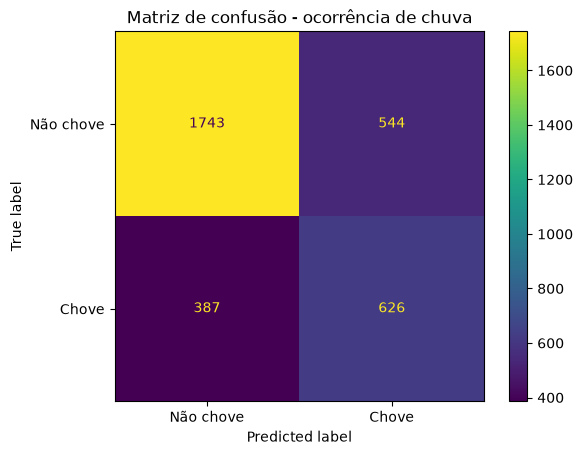

In [5]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
y_real_validacao = []
y_pred_validacao = []

for idx_train, idx_val in tscv.split(X_class):

    X_tr = X_class.iloc[idx_train]
    X_val = X_class.iloc[idx_val]

    y_tr = y_class.iloc[idx_train]
    y_val = y_class.iloc[idx_val]

    modelo_classificador = RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced"
    )

    modelo_classificador.fit(X_tr, y_tr)

    y_pred = modelo_classificador.predict(X_val)

    y_real_validacao.extend(y_val)
    y_pred_validacao.extend(y_pred)

matriz = confusion_matrix(
    y_real_validacao,
    y_pred_validacao
)

print(matriz)

display = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=[
        "Não chove",
        "Chove"
    ]
)

display.plot()
plt.title("Matriz de confusão - ocorrência de chuva")
plt.show()

#### Interpretação da matriz de confusão

A matriz de confusão, construída a partir das previsões dos cinco folds da validação temporal, apresentou **1.743 verdadeiros negativos, 626 verdadeiros positivos, 544 falsos positivos e 387 falsos negativos**.

O classificador identificou aproximadamente **61,8% dos dias com precipitação igual ou superior a 1 mm**, deixando de detectar **38,2% dos eventos observados**.

Além disso, foram registrados 544 falsos positivos, correspondentes a dias classificados como chuvosos nos quais a precipitação observada foi inferior a 1 mm.

Esses resultados evidenciam limitações importantes para a abordagem em duas etapas. Os dias chuvosos classificados incorretamente como secos não são encaminhados ao modelo de regressão da intensidade, resultando em previsões de precipitação nula mesmo quando há ocorrência de chuva.

Dessa forma, torna-se relevante investigar diferentes limiares de decisão, buscando melhorar a identificação dos dias chuvosos sem elevar excessivamente a quantidade de falsos positivos e, consequentemente, os erros na previsão final do volume de precipitação.

### Avaliação de diferentes limiares de classificação

Após a avaliação inicial do classificador, foram investigados diferentes limiares de decisão (*thresholds*) para a identificação de dias chuvosos.

O objetivo dessa análise é verificar se a redução do limiar padrão de 0,50 permite aumentar a sensibilidade do modelo, reduzindo a quantidade de eventos de chuva não identificados.

As probabilidades de classificação foram obtidas utilizando os mesmos cinco folds da validação temporal, mantendo a separação cronológica entre treinamento e validação. Foram analisadas as métricas precision, recall, F1-score e a quantidade de falsos positivos e falsos negativos para cada limiar.

A escolha do limiar será considerada posteriormente em conjunto com o desempenho da regressão de intensidade, uma vez que um maior recall não garante necessariamente menor erro na previsão do volume de chuva.

In [6]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Armazena os valores reais e as probabilidades
y_real_validacao = []
prob_chuva_validacao = []

# Mesmos 5 folds temporais
for idx_train, idx_val in tscv.split(X_class):

    X_tr = X_class.iloc[idx_train]
    X_val = X_class.iloc[idx_val]

    y_tr = y_class.iloc[idx_train]
    y_val = y_class.iloc[idx_val]

    modelo = RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced"
    )

    modelo.fit(X_tr, y_tr)

    # Probabilidade estimada para a classe 1 (chuva)
    probabilidades = modelo.predict_proba(X_val)[:, 1]

    y_real_validacao.extend(y_val)
    prob_chuva_validacao.extend(probabilidades)


# Diferentes thresholds para avaliação
thresholds = [0.30, 0.35, 0.40, 0.45, 0.50]

resultados_thresholds = []

for threshold in thresholds:

    # Converte probabilidade em classificação
    y_pred = (
        np.array(prob_chuva_validacao) >= threshold
    ).astype(int)

    precision = precision_score(y_real_validacao, y_pred)
    recall = recall_score(y_real_validacao, y_pred)
    f1 = f1_score(y_real_validacao, y_pred)

    tn, fp, fn, tp = confusion_matrix(
        y_real_validacao,
        y_pred,
        labels=[0, 1]
    ).ravel()

    resultados_thresholds.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "Falsos_positivos": fp,
        "Falsos_negativos": fn
    })

df_thresholds = pd.DataFrame(resultados_thresholds)

df_thresholds.round(3)

,Threshold,Precision,Recall,F1,Falsos_positivos,Falsos_negativos
0,0.30,0.443,0.851,0.582,1086,151
1,0.35,0.471,0.820,0.598,934,182
2,0.40,0.486,0.760,0.593,814,243
3,0.45,0.512,0.712,0.596,687,292
4,0.50,0.533,0.622,0.574,553,383


#### Análise dos limiares de classificação

A avaliação de diferentes limiares de decisão demonstrou que a redução do threshold aumenta a sensibilidade do classificador para identificação de dias chuvosos, embora também eleve a quantidade de falsos positivos.

Entre os limiares avaliados, o valor de **0,35 apresentou o maior F1-score (0,598)**, com precision de **47,1%** e recall de **82,0%**.

Em comparação com o threshold de 0,50, a quantidade de falsos negativos diminuiu de **383 para 182**, enquanto os falsos positivos aumentaram de **553 para 934**. Esse resultado evidencia o compromisso entre aumentar a identificação dos dias chuvosos e reduzir classificações positivas incorretas.

Considerando a arquitetura em duas etapas, o threshold de **0,35** foi selecionado como candidato para a avaliação conjunta dos componentes de classificação e regressão. Entretanto, sua adequação definitiva dependerá do desempenho obtido na estimativa final do volume de precipitação, considerando as métricas de MAE e RMSE.

## Etapa 2 — Regressão da intensidade da precipitação

Após a avaliação da classificação de ocorrência de chuva, foi implementada a segunda etapa do modelo, destinada à estimativa do volume diário de precipitação.

Nessa abordagem, o regressor é treinado exclusivamente com os registros de treinamento cuja precipitação observada foi igual ou superior a 1 mm. Dessa forma, busca-se modelar a intensidade dos eventos chuvosos sem a influência direta dos numerosos registros de precipitação nula ou muito baixa.

Durante a validação, as previsões dos dois componentes são combinadas. Quando a probabilidade estimada pelo classificador é inferior ao limiar de **0,35**, a precipitação prevista é definida como 0 mm. Caso contrário, utiliza-se a quantidade estimada pelo regressor.

O limiar de 0,35 foi selecionado inicialmente por apresentar o maior F1-score (**0,598**) entre os valores avaliados na etapa de classificação. Entretanto, sua adequação para a previsão da precipitação diária dependerá dos resultados obtidos na avaliação conjunta dos componentes.

A avaliação é realizada por validação temporal com cinco folds, sem utilização do conjunto de teste final. Os resultados serão comparados às métricas da regressão direta obtidas anteriormente.

In [11]:
from sklearn.ensemble import (
    RandomForestClassifier,
    RandomForestRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

import numpy as np
import pandas as pd

threshold = 0.35

resultados_duas_etapas = []

for fold, (idx_train, idx_val) in enumerate(
    tscv.split(X_class),
    start=1
):
    # Dados do fold
    X_tr = X_class.iloc[idx_train]
    X_val = X_class.iloc[idx_val]

    y_tr_class = y_class.iloc[idx_train]

    y_tr_mm = treino_duas_etapas[
        "precipitacao_diaria_mm"
    ].iloc[idx_train]

    y_val_mm = treino_duas_etapas[
        "precipitacao_diaria_mm"
    ].iloc[idx_val]

    # ETAPA 1 - Classificação
    classificador = RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced"
    )

    classificador.fit(X_tr, y_tr_class)

    prob_chuva = classificador.predict_proba(
        X_val
    )[:, 1]

    previsao_chuva = prob_chuva >= threshold

    # ETAPA 2 - Regressão
    # Somente dias realmente chuvosos do treino
    mascara_chuva_treino = y_tr_mm >= 1

    regressor = RandomForestRegressor(
        n_estimators=300,
        max_depth=10,
        min_samples_split=5,
        min_samples_leaf=10,
        max_features=0.5,
        random_state=42,
        n_jobs=-1
    )

    regressor.fit(
        X_tr.loc[mascara_chuva_treino],
        y_tr_mm.loc[mascara_chuva_treino]
    )

    # Previsão final das duas etapas
    y_pred = np.zeros(len(X_val))

    if previsao_chuva.any():
        y_pred[previsao_chuva] = regressor.predict(
            X_val.loc[previsao_chuva]
        )

    # Avaliação em todos os dias do fold
    mae = mean_absolute_error(
        y_val_mm,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_val_mm,
            y_pred
        )
    )

    resultados_duas_etapas.append({
        "Fold": fold,
        "MAE_mm": mae,
        "RMSE_mm": rmse
    })

    print(
        f"Fold {fold} | "
        f"MAE: {mae:.3f} mm | "
        f"RMSE: {rmse:.3f} mm"
    )

df_resultados_duas_etapas = pd.DataFrame(
    resultados_duas_etapas
)

print("\nMédia dos folds")
print(
    f"MAE médio: "
    f"{df_resultados_duas_etapas['MAE_mm'].mean():.3f} mm"
)
print(
    f"RMSE médio: "
    f"{df_resultados_duas_etapas['RMSE_mm'].mean():.3f} mm"
)

Fold 1 | MAE: 7.988 mm | RMSE: 12.133 mm
Fold 2 | MAE: 7.768 mm | RMSE: 11.827 mm
Fold 3 | MAE: 7.473 mm | RMSE: 11.798 mm
Fold 4 | MAE: 7.735 mm | RMSE: 13.068 mm
Fold 5 | MAE: 6.438 mm | RMSE: 10.111 mm

Média dos folds
MAE médio: 7.481 mm
RMSE médio: 11.788 mm


#### Avaliação inicial da abordagem em duas etapas

A abordagem em duas etapas, composta por um classificador de ocorrência de precipitação e um regressor condicionado aos dias chuvosos, apresentou **MAE médio de 7,481 mm** e **RMSE médio de 11,788 mm** na validação temporal, utilizando o limiar de classificação de 0,35.

Esses resultados foram inferiores aos obtidos pela Random Forest de regressão direta otimizada, que apresentou **MAE médio de 5,497 mm** e **RMSE médio de 10,175 mm**. Em termos relativos, a abordagem em duas etapas apresentou MAE aproximadamente **36,1% maior** e RMSE **15,9% maior**, indicando menor precisão na estimativa do acumulado diário de precipitação.

O desempenho inferior pode estar relacionado à propagação dos erros de classificação para a etapa de regressão, especialmente nos casos em que dias chuvosos são classificados como secos ou dias secos são encaminhados ao modelo de intensidade. Além disso, os hiperparâmetros do regressor condicional não foram otimizados especificamente para essa formulação.

Assim, os resultados iniciais não demonstraram vantagem da arquitetura em duas etapas para a previsão do acumulado diário de precipitação, sendo necessária uma avaliação complementar dos limiares de classificação antes de estabelecer conclusões definitivas.

### Avaliação dos limiares na previsão final de precipitação

Embora o limiar de classificação de **0,35** tenha apresentado o maior F1-score (**0,598**) entre os valores inicialmente avaliados, esse resultado não garante o melhor desempenho na estimativa do volume diário de precipitação.

Para investigar essa questão, foram avaliados diferentes limiares de classificação, considerando o desempenho conjunto do classificador de ocorrência e do regressor de intensidade.

A análise foi realizada utilizando os mesmos cinco folds da validação temporal, com as métricas MAE e RMSE calculadas sobre as previsões finais em milímetros.

O objetivo foi identificar se a alteração do limiar de classificação permite reduzir os erros da arquitetura em duas etapas, mantendo o conjunto de teste final fora do processo de seleção.

In [12]:
thresholds = [
    0.30,
    0.35,
    0.40,
    0.45,
    0.50,
    0.55,
    0.60,
    0.65,
    0.70,
    0.75
]

resultados_thresholds_mm = []

for fold, (idx_train, idx_val) in enumerate(
    tscv.split(X_class),
    start=1
):
    # Dados do fold
    X_tr = X_class.iloc[idx_train]
    X_val = X_class.iloc[idx_val]

    y_tr_class = y_class.iloc[idx_train]

    y_tr_mm = treino_duas_etapas[
        "precipitacao_diaria_mm"
    ].iloc[idx_train]

    y_val_mm = treino_duas_etapas[
        "precipitacao_diaria_mm"
    ].iloc[idx_val]

    # Etapa 1: classificador
    classificador = RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced"
    )

    classificador.fit(X_tr, y_tr_class)

    prob_chuva = classificador.predict_proba(
        X_val
    )[:, 1]

    # Etapa 2: regressor treinado somente em dias chuvosos
    mascara_chuva = y_tr_mm >= 1

    regressor = RandomForestRegressor(
        n_estimators=300,
        max_depth=10,
        min_samples_split=5,
        min_samples_leaf=10,
        max_features=0.5,
        random_state=42,
        n_jobs=-1
    )

    regressor.fit(
        X_tr.loc[mascara_chuva],
        y_tr_mm.loc[mascara_chuva]
    )

    # Calcula a intensidade para todos os dias da validação
    intensidade_prevista = np.maximum(
        regressor.predict(X_val),
        0
    )

    # Compara diferentes thresholds
    for threshold in thresholds:

        previsao_chuva = prob_chuva >= threshold

        y_pred_mm = np.where(
            previsao_chuva,
            intensidade_prevista,
            0.0
        )

        mae = mean_absolute_error(
            y_val_mm,
            y_pred_mm
        )

        rmse = np.sqrt(
            mean_squared_error(
                y_val_mm,
                y_pred_mm
            )
        )

        resultados_thresholds_mm.append({
            "Fold": fold,
            "Threshold": threshold,
            "MAE_mm": mae,
            "RMSE_mm": rmse
        })

# Consolida os resultados dos 5 folds
df_thresholds_mm = pd.DataFrame(
    resultados_thresholds_mm
)

resumo_thresholds_mm = (
    df_thresholds_mm
    .groupby("Threshold")
    .agg(
        MAE_medio_mm=("MAE_mm", "mean"),
        RMSE_medio_mm=("RMSE_mm", "mean")
    )
    .reset_index()
    .sort_values("RMSE_medio_mm")
)

resumo_thresholds_mm.round(3)

,Threshold,MAE_medio_mm,RMSE_medio_mm
4,0.50,6.166,11.238
8,0.70,4.662,11.248
5,0.55,5.733,11.252
7,0.65,4.987,11.327
6,0.60,5.384,11.363
3,0.45,6.629,11.408
9,0.75,4.461,11.440
2,0.40,7.065,11.599
1,0.35,7.481,11.788
0,0.30,7.988,12.016


#### Análise dos limiares na previsão final de precipitação

A avaliação conjunta dos componentes de classificação e regressão demonstrou que o limiar com melhor desempenho na identificação da ocorrência de chuva não corresponde necessariamente ao limiar que minimiza os erros na estimativa do acumulado diário.

Embora o threshold de **0,35** tenha apresentado o maior F1-score na etapa de classificação (**0,598**), sua utilização na arquitetura completa resultou em MAE médio de **7,481 mm** e RMSE médio de **11,788 mm**.

O menor MAE foi obtido com o threshold de **0,75**, atingindo **4,461 mm**. Por outro lado, o menor RMSE foi observado com o threshold de **0,50**, alcançando **11,238 mm**.

A redução progressiva do MAE com o aumento do limiar pode estar associada à maior frequência de previsões nulas, favorecendo o desempenho médio em uma base caracterizada pela predominância de dias secos ou com precipitação reduzida.

Em comparação com a Random Forest de regressão direta otimizada, que apresentou MAE médio de **5,497 mm** e RMSE médio de **10,175 mm**, a arquitetura em duas etapas alcançou valores inferiores de MAE em alguns limiares, mas não apresentou melhoria no RMSE.

Dessa forma, a escolha do limiar mais adequado não deve considerar exclusivamente o menor MAE, sendo necessária uma análise complementar da frequência de previsões nulas, do desempenho em eventos chuvosos e da comparação com o baseline de precipitação zero.

In [13]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Baseline: prever sempre 0 mm
previsao_zero = np.zeros(len(X_class))

maes_zero = []
rmses_zero = []

for idx_train, idx_val in tscv.split(X_class):

    y_val = treino_duas_etapas[
        "precipitacao_diaria_mm"
    ].iloc[idx_val]

    y_pred = previsao_zero[idx_val]

    mae = mean_absolute_error(y_val, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_val, y_pred)
    )

    maes_zero.append(mae)
    rmses_zero.append(rmse)

print(f"MAE médio - Sempre zero: {np.mean(maes_zero):.3f} mm")
print(f"RMSE médio - Sempre zero: {np.mean(rmses_zero):.3f} mm")

MAE médio - Sempre zero: 4.284 mm
RMSE médio - Sempre zero: 11.516 mm


#### Comparação com o baseline de precipitação zero

Como referência adicional, foi avaliado um baseline que prevê precipitação igual a 0 mm para todas as observações da validação temporal.

Essa abordagem apresentou **MAE médio de 4,284 mm** e **RMSE médio de 11,516 mm**.

O MAE obtido foi inferior aos resultados da Random Forest de regressão direta otimizada (**5,497 mm**) e da arquitetura em duas etapas em todos os limiares avaliados, incluindo o threshold de 0,75, que apresentou MAE de **4,461 mm**.

Esse resultado está associado à predominância de dias secos ou com baixos acumulados de precipitação, condição que favorece previsões próximas de zero quando avaliadas exclusivamente pelo erro absoluto médio.

Entretanto, o baseline sempre zero não possui capacidade de identificar a ocorrência de chuva ou estimar adequadamente eventos intensos. Essa limitação também se reflete no RMSE, que atingiu **11,516 mm**, superior ao valor de **10,175 mm** obtido pela Random Forest de regressão direta.

A comparação demonstra que a interpretação do desempenho dos modelos deve considerar simultaneamente diferentes métricas e as características da distribuição da precipitação diária. Em particular, a minimização isolada do MAE pode favorecer estratégias conservadoras que apresentam baixa capacidade de representação dos eventos chuvosos.

Dessa forma, os resultados reforçam a importância de avaliar não apenas o erro médio global, mas também a capacidade dos modelos de representar a magnitude da precipitação, especialmente em eventos de maior intensidade.

### Frequência de previsões de chuva por limiar de classificação

Para investigar o comportamento da arquitetura em duas etapas, foi analisada a proporção de dias classificados como chuvosos e não chuvosos para diferentes limiares de decisão.

Essa análise busca verificar se a redução do MAE observada com o aumento do threshold está associada a uma maior frequência de previsões de precipitação nula.

Foram avaliados os limiares de 0,40, 0,55 e 0,75, utilizando as probabilidades estimadas pelo classificador nos cinco folds da validação temporal.

In [14]:
thresholds_analise = [0.40, 0.55, 0.75]

probabilidades = np.array(prob_chuva_validacao)

resultados_frequencia = []

for threshold in thresholds_analise:

    # Identifica os dias classificados como chuvosos
    previsao_chuva = probabilidades >= threshold

    total_dias = len(previsao_chuva)

    dias_chuva = previsao_chuva.sum()
    dias_sem_chuva = total_dias - dias_chuva

    resultados_frequencia.append({
        "Threshold": threshold,
        "Total_dias": total_dias,
        "Dias_previstos_chuva": dias_chuva,
        "Dias_previstos_sem_chuva": dias_sem_chuva,
        "Percentual_chuva": dias_chuva / total_dias * 100,
        "Percentual_sem_chuva": dias_sem_chuva / total_dias * 100
    })

df_frequencia = pd.DataFrame(resultados_frequencia)

df_frequencia.round(2)

,Threshold,Total_dias,Dias_previstos_chuva,Dias_previstos_sem_chuva,Percentual_chuva,Percentual_sem_chuva
0,0.40,3300,1584,1716,48.00,52.00
1,0.55,3300,933,2367,28.27,71.73
2,0.75,3300,142,3158,4.30,95.70


#### Análise da frequência de previsões por limiar

A análise da frequência de classificações demonstrou que o aumento do limiar de decisão reduz significativamente a quantidade de dias identificados como chuvosos pela arquitetura em duas etapas.

Com o threshold de **0,40**, aproximadamente **48,00%** dos registros foram classificados como chuvosos, enquanto **52,00%** foram classificados como secos. Ao elevar o limiar para **0,55**, a proporção de dias classificados como secos aumentou para **71,73%**.

No threshold de **0,75**, que apresentou o menor MAE da arquitetura completa (**4,461 mm**), apenas **4,30%** das observações foram classificadas como chuvosas, enquanto **95,70%** receberam classificação de ausência de chuva.

Esse comportamento ajuda a explicar a redução do MAE com o aumento do threshold. Como a série apresenta predominância de dias sem precipitação ou com baixos acumulados, a atribuição mais frequente de previsões nulas pode reduzir os erros absolutos médios, mesmo quando o modelo deixa de identificar eventos chuvosos.

Entretanto, essa estratégia apresenta limitações importantes. A classificação de grande parte dos registros como secos compromete a capacidade da arquitetura de representar a ocorrência e a intensidade da precipitação, especialmente nos eventos menos frequentes.

Essa interpretação é reforçada pelo baseline que prevê sempre 0 mm, cujo **MAE médio de 4,284 mm** foi inferior ao de todas as configurações avaliadas da arquitetura em duas etapas.

Dessa forma, os resultados indicam que a redução do MAE observada em limiares elevados não representa, isoladamente, uma melhoria na capacidade de previsão dos eventos de precipitação. A avaliação deve considerar conjuntamente MAE, RMSE e a capacidade de identificação de dias chuvosos.

## Conclusão da modelagem em duas etapas

Neste experimento, foi investigada uma abordagem alternativa para a previsão da precipitação diária, baseada na separação entre ocorrência e intensidade da chuva. A arquitetura utilizou um classificador Random Forest para identificar dias com precipitação igual ou superior a 1 mm e um regressor Random Forest para estimar o volume de chuva nos dias classificados como chuvosos.

A classificação apresentou desempenho moderado, com **recall médio de 0,618**, **precision média de 0,536** e **F1-score médio de 0,574** na validação temporal, considerando o limiar padrão de 0,50. A avaliação de diferentes limiares demonstrou que a redução do threshold aumentou a sensibilidade do classificador, permitindo identificar uma parcela maior dos eventos chuvosos, mas também elevando a quantidade de falsos positivos.

Na avaliação conjunta das duas etapas, o limiar de **0,50 apresentou o menor RMSE médio**, de **11,238 mm**, com MAE médio de **6,166 mm**. Por outro lado, o limiar de **0,75 apresentou o menor MAE médio**, de **4,461 mm**, mas RMSE de **11,440 mm**.

A análise da frequência de previsões demonstrou que, com o limiar de 0,75, aproximadamente **95,70% dos dias foram classificados como sem chuva**. Esse comportamento, associado ao MAE médio de **4,284 mm** obtido pelo baseline que prevê sempre 0 mm, evidencia que a minimização isolada do erro absoluto médio pode favorecer estratégias de previsão excessivamente conservadoras.

Em comparação, a Random Forest multivariada de regressão direta otimizada apresentou **MAE médio de 5,497 mm** e **RMSE médio de 10,175 mm** na validação temporal. Embora determinadas configurações da arquitetura em duas etapas tenham apresentado valores inferiores de MAE, nenhuma delas superou a regressão direta em RMSE.

Dessa forma, **a modelagem em duas etapas não demonstrou vantagem consistente sobre a regressão direta para a previsão do acumulado diário de precipitação**, considerando os dados, atributos e configurações empregados.

Os resultados também indicam que a distinção entre ocorrência e intensidade, isoladamente, não foi suficiente para superar as limitações identificadas. Trabalhos futuros poderão investigar a otimização específica dos modelos de classificação e regressão, outras técnicas de previsão probabilística e a incorporação de informações meteorológicas adicionais.

Conclui-se que, entre as abordagens investigadas, a **Random Forest multivariada de regressão direta permanece como o modelo principal selecionado**, considerando o desempenho em RMSE, a comparação com os baselines e o objetivo de estimar o acumulado diário de precipitação, sem desconsiderar as limitações observadas na previsão de eventos intensos.